In [1]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

login(token=UserSecretsClient().get_secret("HF_TOKEN"))

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

Found 1 objects


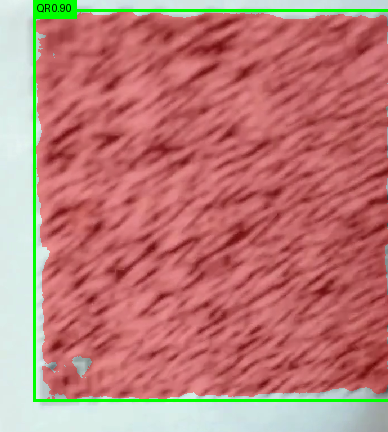

In [9]:
# SAM3 QR segmentation + box drawing. Run in one Kaggle cell (Internet ON, HF_TOKEN secret attached).
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
from transformers import Sam3Processor, Sam3Model
import numpy as np
import torch
from PIL import Image, ImageDraw

login(token=UserSecretsClient().get_secret("HF_TOKEN"))

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Sam3Model.from_pretrained("facebook/sam3").to(device)
processor = Sam3Processor.from_pretrained("facebook/sam3")

# Load image
image_path = "/kaggle/input/datasets/rakshitsawarniitb/blurqr/Screenshot 2026-09-21 193556.png"
image = Image.open(image_path).convert("RGB")

# Segment using text prompt
inputs = processor(images=image, text="QR Code", return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)

# Post-process results
sam3_results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    mask_threshold=0.5,
    target_sizes=inputs.get("original_sizes").tolist()
)[0]
print(f"Found {len(sam3_results['masks'])} objects")
# Results contain:
# - masks: Binary masks resized to original image size
# - boxes: Bounding boxes in absolute pixel coordinates (xyxy format)
# - scores: Confidence scores


# ---------- Draw masks + boxes ----------
def to_np(x):
    return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)


def draw_results(image, results, mask_color=(255, 0, 0), box_color=(0, 255, 0), alpha=0.4):
    vis = np.array(image).astype(np.float32)
    masks = to_np(results["masks"]).astype(bool)
    boxes = to_np(results["boxes"])
    scores = to_np(results["scores"])

    for m in masks:                                   # translucent mask overlay
        vis[m] = (1 - alpha) * vis[m] + alpha * np.array(mask_color)

    out = Image.fromarray(vis.astype(np.uint8))
    draw = ImageDraw.Draw(out)
    lw = max(3, out.width // 300)                     # line width scales with image size
    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = [float(v) for v in box]
        draw.rectangle([x1, y1, x2, y2], outline=box_color, width=lw)
        label = f"QR {score:.2f}"
        tw = draw.textlength(label)
        ty = max(y1 - 18, 0)
        draw.rectangle([x1, ty, x1 + tw + 8, ty + 18], fill=box_color)
        draw.text((x1 + 4, ty + 2), label, fill=(0, 0, 0))
    return out


vis = draw_results(image, sam3_results)
vis.save("qr_sam3_result.jpg")
display(vis.resize((min(vis.width, 1000), int(vis.height * min(vis.width, 1000) / vis.width))))

In [3]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 5.4 MB/s eta 0:00:00


Found 0 objects
boxes (xyxy): []
scores: []


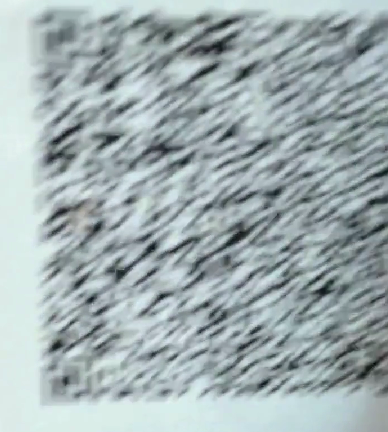

In [10]:
# Final version: QR code detection + masks. Paste into ONE Kaggle cell and run.
# Works with no weights (OpenCV path). Set WEIGHTS to use a YOLO model.
import subprocess, sys
import cv2
import numpy as np
import torch
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- CONFIG ----------------
image_path = "/kaggle/input/datasets/rakshitsawarniitb/blurqr/Screenshot 2026-09-21 193556.png"
WEIGHTS = None      # e.g. "/kaggle/input/<your-dataset>/qr_best.pt" (must be QR-trained; COCO has no QR class)
CONF = 0.25         # YOLO confidence threshold
# ----------------------------------------

image = Image.open(image_path).convert("RGB")
W, H = image.size
empty = lambda: {"masks": np.zeros((0, H, W), np.uint8), "boxes": np.zeros((0, 4)), "scores": np.zeros(0)}


def pack(quads):
    """quads: list of (4,2) corner arrays in original-image pixels -> results dict."""
    if not len(quads):
        return empty()
    masks, boxes = [], []
    for q in quads:
        q = np.asarray(q, dtype=np.float32).reshape(4, 2)
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [q.astype(np.int32)], 1)
        masks.append(m)
        boxes.append([q[:, 0].min(), q[:, 1].min(), q[:, 0].max(), q[:, 1].max()])
    return {"masks": np.array(masks), "boxes": np.array(boxes), "scores": np.ones(len(masks))}


def run_yolo(weights, image, conf):
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
        from ultralytics import YOLO
    res = YOLO(weights).predict(image, conf=conf, device=device, retina_masks=True, verbose=False)[0]
    boxes = res.boxes.xyxy.cpu().numpy()
    scores = res.boxes.conf.cpu().numpy()
    if res.masks is not None:                       # -seg model: real masks
        masks = (res.masks.data.cpu().numpy() > 0.5).astype(np.uint8)
    else:                                           # detect model: fill boxes
        masks = np.zeros((len(boxes), H, W), np.uint8)
        for i, (x1, y1, x2, y2) in enumerate(boxes.astype(int)):
            masks[i, max(y1, 0):y2, max(x1, 0):x2] = 1
    return {"masks": masks, "boxes": boxes, "scores": scores}


def run_opencv(image):
    """Tries several detectors x scales x preprocessings until one finds a code."""
    bgr = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(gray)
    variants = [bgr, gray, clahe]

    detectors = []
    if hasattr(cv2, "QRCodeDetectorAruco"):         # OpenCV >= 4.8, more robust
        detectors.append(cv2.QRCodeDetectorAruco())
    detectors.append(cv2.QRCodeDetector())

    for scale in (1.0, 0.5, 0.33, 0.25, 0.15, 2.0):  # big phone photos often need downscaling
        for v in variants:
            img = cv2.resize(v, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            for det in detectors:
                try:
                    ok, pts = det.detectMulti(img)
                except cv2.error:
                    continue
                if ok and pts is not None and len(pts):
                    return pack(list(pts / scale))
    return empty()


yolo_results = empty()
if WEIGHTS:
    yolo_results = run_yolo(WEIGHTS, image, CONF)
    if len(yolo_results["masks"]) == 0:
        print("YOLO found nothing, falling back to OpenCV...")
if len(yolo_results["masks"]) == 0:
    yolo_results = run_opencv(image)

print(f"Found {len(yolo_results['masks'])} objects")
print("boxes (xyxy):", yolo_results["boxes"].round(1).tolist())
print("scores:", yolo_results["scores"].round(3).tolist())

# Visual check -> shows in notebook and saves qr_result.jpg
vis = np.array(image).copy()
for m, b in zip(yolo_results["masks"], yolo_results["boxes"]):
    mb = m.astype(bool)
    vis[mb] = (0.5 * vis[mb] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    x1, y1, x2, y2 = map(int, b)
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), max(3, W // 300))
out = Image.fromarray(vis)
out.save("qr_result.jpg")
try:
    from IPython.display import display
    display(out.resize((min(W, 1000), int(H * min(W, 1000) / W))))
except Exception:
    pass

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import to_rgb


def _np(x):
    """Accepts torch tensors or numpy arrays."""
    return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)


def compare_plot(image, results_by_method, title=None, alpha=0.45, figsize_per_panel=8, save_path=None):
    """
    Side-by-side comparison of QR detections from different methods on the same image.

    image:              PIL image (or HxWx3 array)
    results_by_method:  {"SAM3": results_a, "YOLO": results_b, ...}
                        each results dict has "masks" (N,H,W), "boxes" (N,4 xyxy px), "scores" (N,)
    title:              optional figure title (e.g. the image filename)
    save_path:          optional path to save the figure (e.g. "comparison.png")
    """
    img = np.array(image)
    H, W = img.shape[:2]
    n = len(results_by_method)
    colors = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46f0f0"]

    fig, axes = plt.subplots(1, n, figsize=(figsize_per_panel * n, figsize_per_panel * H / W + 1), squeeze=False)

    for ax, (name, res) in zip(axes[0], results_by_method.items()):
        masks = _np(res["masks"]).astype(bool).reshape(-1, H, W)
        boxes = _np(res["boxes"]).reshape(-1, 4)
        scores = _np(res["scores"]).reshape(-1)

        # OpenCV-style detectors give no confidence (all exactly 1.0), so don't print fake scores
        has_conf = not np.all(scores == 1.0) if len(scores) else False

        vis = img.astype(np.float32)
        for i, m in enumerate(masks):                                   # translucent masks
            c = np.array(to_rgb(colors[i % len(colors)])) * 255
            vis[m] = (1 - alpha) * vis[m] + alpha * c
        ax.imshow(vis.astype(np.uint8))

        for i, (b, s) in enumerate(zip(boxes, scores)):                 # boxes + labels
            c = colors[i % len(colors)]
            x1, y1, x2, y2 = [float(v) for v in b]
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=3))
            label = f"QR #{i + 1}" + (f"  {s:.2f}" if has_conf else "")
            ax.text(x1, max(y1 - 10, 0), label, color="white", fontsize=11, fontweight="bold", va="bottom",
                    bbox=dict(facecolor=c, edgecolor="none", pad=2.5))

        sub = f"{len(boxes)} detection{'s' if len(boxes) != 1 else ''}"
        if has_conf:
            sub += f" | mean conf {scores.mean():.2f}"
        elif len(boxes):
            sub += " | no confidence score"
        ax.set_title(f"{name}\n{sub}", fontsize=14, fontweight="bold")
        ax.set_xlabel(f"image size: {W} x {H} px")
        ax.set_xticks([]); ax.set_yticks([])

    if title:
        fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    return fig

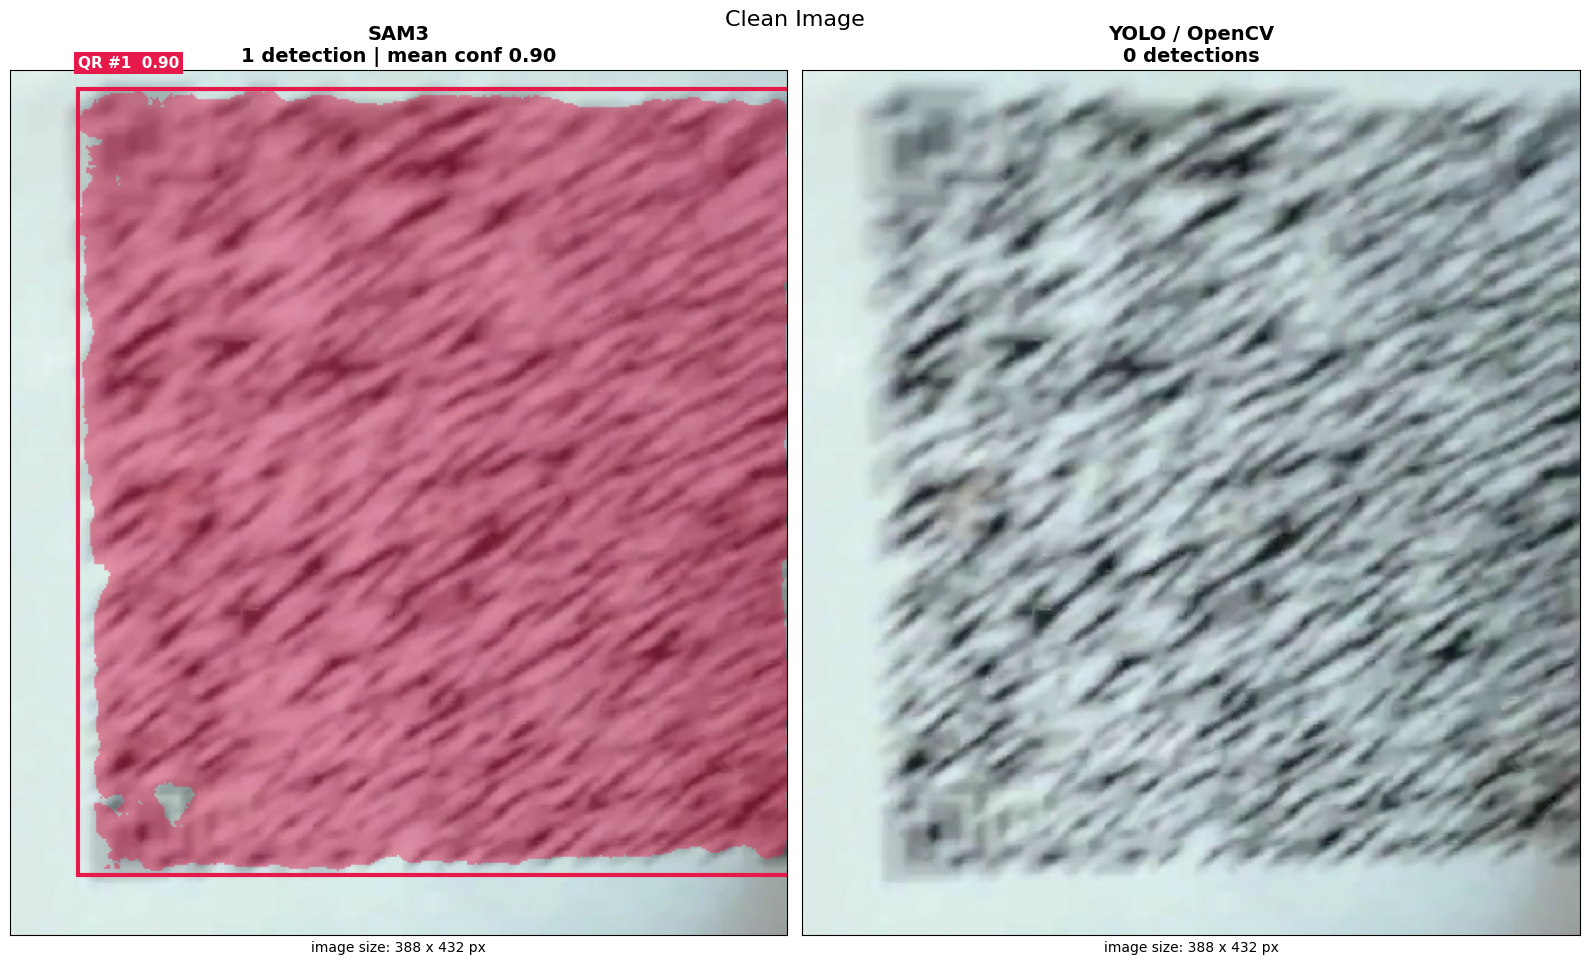

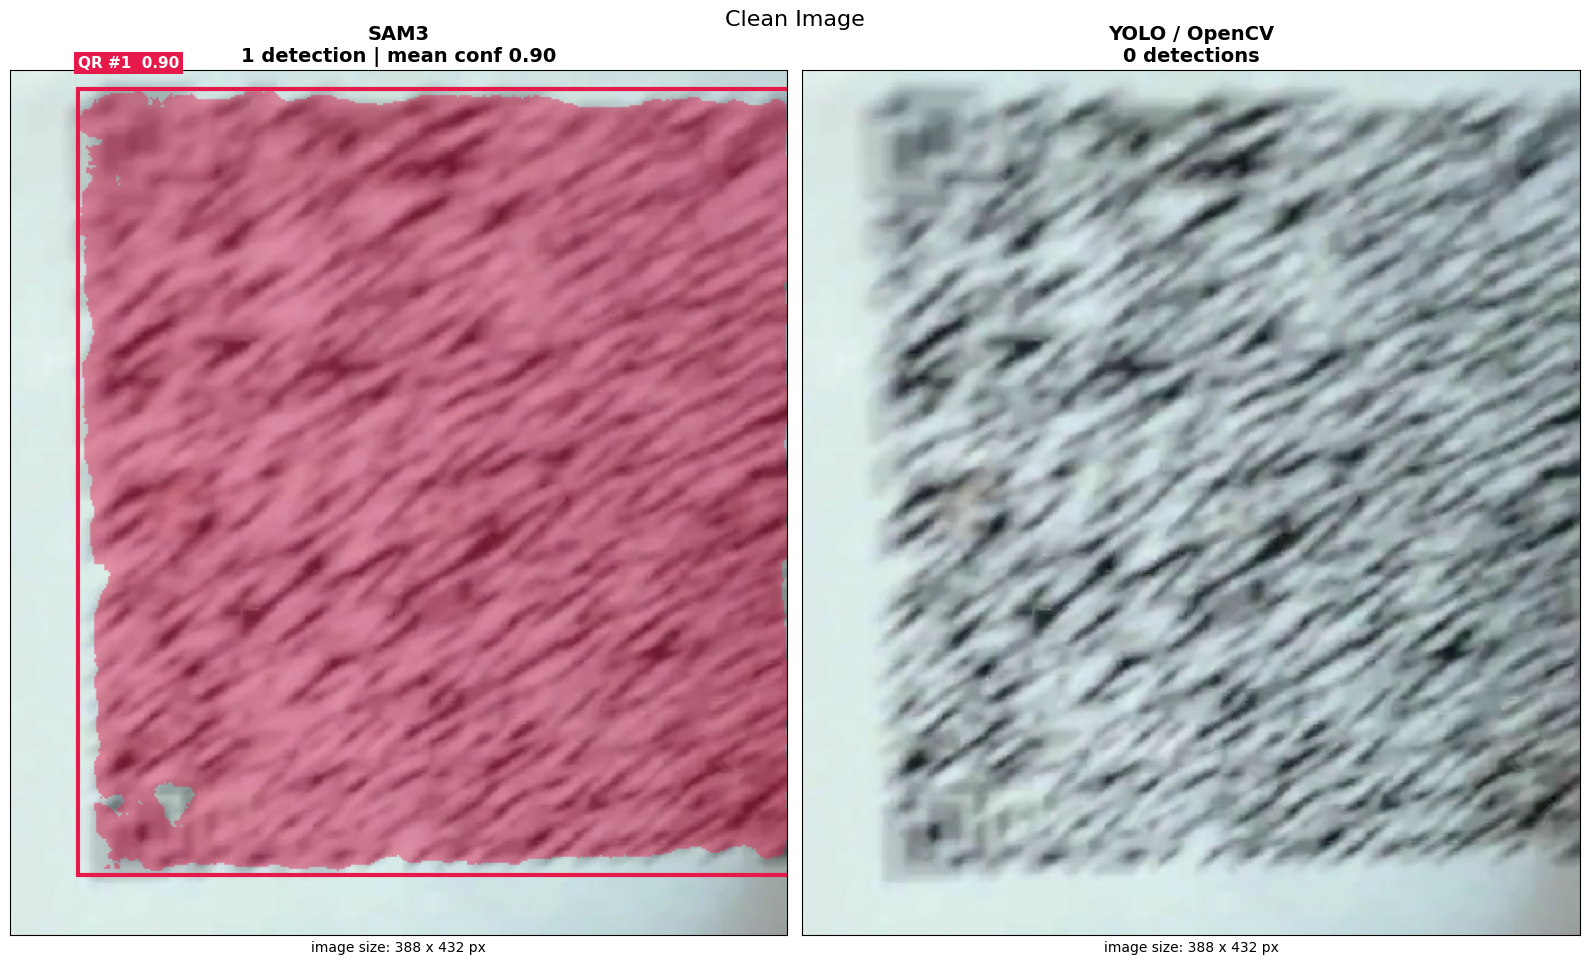

In [12]:
compare_plot(image, {"SAM3": sam3_results, "YOLO / OpenCV": yolo_results}, title="Clean Image", save_path="comparison.png")

In [ ]:
"""
benchmark_qr_detectors.py

Pulls every image from the RakshitAi/IITB-BuggyQR Hugging Face dataset
(clean reference photos + motion-blurred video frames) and benchmarks the
YOLO/OpenCV pipeline against SAM3 on each one.

Paste into ONE Kaggle cell and run. Internet must be ON. If the dataset is
private, attach an HF_TOKEN secret (Add-ons -> Secrets).

Requires:
    pip install -q ultralytics transformers huggingface_hub opencv-python-headless matplotlib pandas torch pillow
"""

import glob
import os
import subprocess
import sys
import time

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import snapshot_download
from matplotlib.colors import to_rgb
from PIL import Image, ImageDraw

try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    login(token=UserSecretsClient().get_secret("HF_TOKEN"))
except Exception:
    pass  # public repo, or no Kaggle secret attached

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- CONFIG ----------------
REPO_ID = "RakshitAi/IITB-BuggyQR"
LOCAL_DIR = "/kaggle/working/buggyqr_data"
INCLUDE_REFERENCE_PHOTOS = True
INCLUDE_FRAMES = True
MAX_FRAMES_PER_SESSION = None  # evenly sampled per session; None = every frame (slow, could be 100s)
WEIGHTS = None                 # YOLO weights path (must be QR-trained); None = OpenCV fallback
CONF = 0.25
SAVE_PLOTS = True
PLOTS_DIR = "/kaggle/working/qr_benchmark_plots"
MAX_PLOTS = None                # cap on saved comparison plots; None = save one for every image
DISPLAY_PLOTS_INLINE = True     # show every saved plot in the notebook after the run
# ----------------------------------------


# ============================================================
# 1. Pull every image from the dataset
# ============================================================
def pull_dataset_images(
    repo_id=REPO_ID,
    local_dir=LOCAL_DIR,
    include_reference_photos=INCLUDE_REFERENCE_PHOTOS,
    include_frames=INCLUDE_FRAMES,
    max_frames_per_session=MAX_FRAMES_PER_SESSION,
):
    """
    Downloads images from the HF dataset repo and returns a list of dicts:
        {"path", "qr_id", "session_id", "source"}  source is "reference" or "frame"
    Frames are sampled evenly across each session (not just the first N) so
    the sample still spans the whole video.
    """
    patterns = []
    if include_reference_photos:
        patterns.append("raw/reference_photos/*")
    if include_frames:
        patterns.append("frames/**/*.jpg")

    snapshot_download(
        repo_id=repo_id,
        repo_type="dataset",
        local_dir=local_dir,
        allow_patterns=patterns or None,
    )

    items = []
    for p in sorted(glob.glob(os.path.join(local_dir, "raw", "reference_photos", "*"))):
        if p.lower().endswith((".jpg", ".jpeg", ".png")):
            qr_id = os.path.splitext(os.path.basename(p))[0]
            items.append({"path": p, "qr_id": qr_id, "session_id": None, "source": "reference"})

    for sdir in sorted(glob.glob(os.path.join(local_dir, "frames", "*"))):
        session_id = os.path.basename(sdir)
        qr_id = session_id.rsplit("_", 2)[0]  # strip _<date>_<take>
        frame_paths = sorted(glob.glob(os.path.join(sdir, "*.jpg")))
        if max_frames_per_session is not None and len(frame_paths) > max_frames_per_session:
            idx = np.linspace(0, len(frame_paths) - 1, max_frames_per_session).astype(int)
            frame_paths = [frame_paths[i] for i in sorted(set(idx))]
        for p in frame_paths:
            items.append({"path": p, "qr_id": qr_id, "session_id": session_id, "source": "frame"})

    n_ref = sum(i["source"] == "reference" for i in items)
    n_frm = sum(i["source"] == "frame" for i in items)
    print(f"Pulled {len(items)} images ({n_ref} reference, {n_frm} frames)")
    return items


# ============================================================
# 2. Detectors (from your existing cells, unchanged logic)
# ============================================================
_yolo_model = None
_sam3_model = None
_sam3_processor = None


def _pack(quads, H, W):
    if not len(quads):
        return {"masks": np.zeros((0, H, W), np.uint8), "boxes": np.zeros((0, 4)), "scores": np.zeros(0)}
    masks, boxes = [], []
    for q in quads:
        q = np.asarray(q, dtype=np.float32).reshape(4, 2)
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [q.astype(np.int32)], 1)
        masks.append(m)
        boxes.append([q[:, 0].min(), q[:, 1].min(), q[:, 0].max(), q[:, 1].max()])
    return {"masks": np.array(masks), "boxes": np.array(boxes), "scores": np.ones(len(masks))}


def run_opencv(image):
    """Tries several detectors x scales x preprocessings until one finds a code."""
    W, H = image.size
    bgr = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(gray)
    variants = [bgr, gray, clahe]

    detectors = []
    if hasattr(cv2, "QRCodeDetectorAruco"):
        detectors.append(cv2.QRCodeDetectorAruco())
    detectors.append(cv2.QRCodeDetector())

    for scale in (1.0, 0.5, 0.33, 0.25, 0.15, 2.0):
        for v in variants:
            img = cv2.resize(v, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            for det in detectors:
                try:
                    ok, pts = det.detectMulti(img)
                except cv2.error:
                    continue
                if ok and pts is not None and len(pts):
                    return _pack(list(pts / scale), H, W)
    return {"masks": np.zeros((0, H, W), np.uint8), "boxes": np.zeros((0, 4)), "scores": np.zeros(0)}


def run_yolo_or_opencv(image, weights=WEIGHTS, conf=CONF):
    """YOLO if weights are given (falls back to OpenCV if it finds nothing), else OpenCV directly."""
    global _yolo_model
    W, H = image.size
    if weights:
        if _yolo_model is None:
            try:
                from ultralytics import YOLO
            except ImportError:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
                from ultralytics import YOLO
            _yolo_model = YOLO(weights)
        res = _yolo_model.predict(image, conf=conf, device=device, retina_masks=True, verbose=False)[0]
        boxes = res.boxes.xyxy.cpu().numpy()
        scores = res.boxes.conf.cpu().numpy()
        if len(boxes):
            if res.masks is not None:
                masks = (res.masks.data.cpu().numpy() > 0.5).astype(np.uint8)
            else:
                masks = np.zeros((len(boxes), H, W), np.uint8)
                for i, (x1, y1, x2, y2) in enumerate(boxes.astype(int)):
                    masks[i, max(y1, 0):y2, max(x1, 0):x2] = 1
            return {"masks": masks, "boxes": boxes, "scores": scores}
    return run_opencv(image)


def run_sam3(image, threshold=0.5, mask_threshold=0.5):
    global _sam3_model, _sam3_processor
    from transformers import Sam3Model, Sam3Processor

    if _sam3_model is None:
        _sam3_model = Sam3Model.from_pretrained("facebook/sam3").to(device)
        _sam3_processor = Sam3Processor.from_pretrained("facebook/sam3")

    inputs = _sam3_processor(images=image, text="QR Code", return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = _sam3_model(**inputs)
    res = _sam3_processor.post_process_instance_segmentation(
        outputs, threshold=threshold, mask_threshold=mask_threshold,
        target_sizes=inputs.get("original_sizes").tolist(),
    )[0]

    def to_np(x):
        return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)

    return {"masks": to_np(res["masks"]), "boxes": to_np(res["boxes"]), "scores": to_np(res["scores"])}


# ============================================================
# 3. Side-by-side plot (from your existing cell, unchanged logic)
# ============================================================
def compare_plot(image, results_by_method, title=None, alpha=0.45, figsize_per_panel=6, save_path=None):
    img = np.array(image)
    H, W = img.shape[:2]
    n = len(results_by_method)
    colors = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46f0f0"]

    fig, axes = plt.subplots(1, n, figsize=(figsize_per_panel * n, figsize_per_panel * H / W + 1), squeeze=False)
    for ax, (name, res) in zip(axes[0], results_by_method.items()):
        masks = np.asarray(res["masks"]).astype(bool).reshape(-1, H, W)
        boxes = np.asarray(res["boxes"]).reshape(-1, 4)
        scores = np.asarray(res["scores"]).reshape(-1)
        has_conf = not np.all(scores == 1.0) if len(scores) else False

        vis = img.astype(np.float32)
        for i, m in enumerate(masks):
            c = np.array(to_rgb(colors[i % len(colors)])) * 255
            vis[m] = (1 - alpha) * vis[m] + alpha * c
        ax.imshow(vis.astype(np.uint8))

        for i, (b, s) in enumerate(zip(boxes, scores)):
            c = colors[i % len(colors)]
            x1, y1, x2, y2 = [float(v) for v in b]
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=3))
            label = f"QR #{i + 1}" + (f"  {s:.2f}" if has_conf else "")
            ax.text(x1, max(y1 - 10, 0), label, color="white", fontsize=10, fontweight="bold", va="bottom",
                    bbox=dict(facecolor=c, edgecolor="none", pad=2.5))

        sub = f"{len(boxes)} detection{'s' if len(boxes) != 1 else ''}"
        sub += f" | mean conf {scores.mean():.2f}" if has_conf and len(boxes) else (" | no confidence score" if len(boxes) else "")
        ax.set_title(f"{name}\n{sub}", fontsize=12, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])

    if title:
        fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()
    return fig


# ============================================================
# 4. Run the benchmark over every pulled image
# ============================================================
def warm_up_sam3(items):
    """
    Runs SAM3 once on a throwaway image so model download + weight load +
    CUDA init happen here, not inside the first timed image in the loop.
    Without this, whichever image happens to be first absorbs ~2-3 minutes
    of one-time cost and makes SAM3's avg_time_s meaningless.
    """
    if not items:
        return
    print("Warming up SAM3 (downloading/loading weights, priming CUDA)...")
    t0 = time.time()
    _ = run_sam3(Image.open(items[0]["path"]).convert("RGB"))
    print(f"  done in {time.time() - t0:.1f}s (one-time cost, excluded from results)")


def benchmark(items, save_plots=SAVE_PLOTS, plots_dir=PLOTS_DIR, max_plots=MAX_PLOTS):
    """max_plots=None saves a comparison plot for every image (can be hundreds of files)."""
    if save_plots:
        os.makedirs(plots_dir, exist_ok=True)

    warm_up_sam3(items)

    rows = []
    n_plotted = 0
    for i, item in enumerate(items):
        try:
            image = Image.open(item["path"]).convert("RGB")
        except Exception as e:
            print(f"  [skip] could not open {item['path']}: {e}")
            continue

        t0 = time.time()
        yolo_res = run_yolo_or_opencv(image)
        t_yolo = time.time() - t0

        t0 = time.time()
        sam3_res = run_sam3(image)
        t_sam3 = time.time() - t0

        method_label = "YOLO" if WEIGHTS else "OpenCV"
        for method, res, t in [(method_label, yolo_res, t_yolo), ("SAM3", sam3_res, t_sam3)]:
            n = len(res["boxes"])
            rows.append({
                "image": os.path.basename(item["path"]),
                "qr_id": item["qr_id"],
                "session_id": item["session_id"],
                "source": item["source"],
                "method": method,
                "detections": n,
                "detected": n > 0,
                "mean_conf": float(np.mean(res["scores"])) if n else np.nan,
                "time_s": t,
            })

        if save_plots and (max_plots is None or n_plotted < max_plots):
            out_path = os.path.join(plots_dir, f"{i:04d}_{item['qr_id']}_{item['source']}.jpg")
            compare_plot(image, {method_label: yolo_res, "SAM3": sam3_res},
                         title=os.path.basename(item["path"]), save_path=out_path)
            n_plotted += 1

        if (i + 1) % 20 == 0 or (i + 1) == len(items):
            print(f"  processed {i + 1}/{len(items)}")

    return pd.DataFrame(rows)


# ============================================================
# 5. Summary
# ============================================================
def print_summary(df):
    print("\n" + "=" * 60)
    print("OVERALL (all images)")
    print("=" * 60)
    overall = df.groupby("method").agg(
        images=("image", "count"),
        detection_rate=("detected", "mean"),
        avg_detections=("detections", "mean"),
        avg_conf=("mean_conf", "mean"),
        avg_time_s=("time_s", "mean"),
    ).round(3)
    print(overall.to_string())

    print("\n" + "=" * 60)
    print("BY SOURCE (clean reference photo vs. motion-blurred frame)")
    print("=" * 60)
    by_source = df.groupby(["source", "method"]).agg(
        images=("image", "count"),
        detection_rate=("detected", "mean"),
        avg_detections=("detections", "mean"),
        avg_conf=("mean_conf", "mean"),
        avg_time_s=("time_s", "mean"),
    ).round(3)
    print(by_source.to_string())

    print("\n" + "=" * 60)
    print("BY SESSION (frames only)")
    print("=" * 60)
    frames = df[df["source"] == "frame"]
    if len(frames):
        by_session = frames.groupby(["session_id", "method"]).agg(
            frames=("image", "count"),
            detection_rate=("detected", "mean"),
            avg_conf=("mean_conf", "mean"),
        ).round(3)
        print(by_session.to_string())
    else:
        print("(no frames included)")


def display_all_plots(plots_dir=PLOTS_DIR, max_width=1000):
    """Shows every saved comparison plot inline, in filename order."""
    from IPython.display import display

    paths = sorted(glob.glob(os.path.join(plots_dir, "*.jpg")))
    print(f"\nDisplaying {len(paths)} comparison plots from {plots_dir}")
    for path in paths:
        img = Image.open(path)
        print(os.path.basename(path))
        display(img.resize((min(img.width, max_width), int(img.height * min(img.width, max_width) / img.width))))


if __name__ == "__main__":
    print("Pulling dataset...")
    items = pull_dataset_images()

    print("\nRunning benchmark...")
    df = benchmark(items)

    df.to_csv("/kaggle/working/qr_benchmark_results.csv", index=False)
    print("\nSaved per-image results -> /kaggle/working/qr_benchmark_results.csv")
    if SAVE_PLOTS:
        print(f"Saved comparison plots -> {PLOTS_DIR}")

    print_summary(df)

    if SAVE_PLOTS and DISPLAY_PLOTS_INLINE:
        display_all_plots()

In [ ]:
import glob
from IPython.display import display
from PIL import Image

folder_path = "/kaggle/working/qr_benchmark_plots"

for path in sorted(glob.glob(f"{folder_path}/*.jpg")):
    img = Image.open(path)
    print(path.split("/")[-1])
    display(img.resize((min(img.width, 1000), int(img.height * min(img.width, 1000) / img.width))))